# 용접 결함 YOLO 학습 (Colab)

런타임 유형을 **GPU** 로 설정 후 **모두 실행** → 바로 뜨는 **화면 맨 위 입력창에 Roboflow 키 입력** (이후 자동 진행, T4 기준 약 4~5시간)

- 데이터: **Roboflow에서 직접 받아 데이터셋 생성** (빌드 규칙이 바뀌면 자동 재생성)
- 학습: 최대 80 epoch, 20 epoch 동안 개선 없으면 조기 종료. 시간 제한이 필요하면 3번 셀의 `cfg.time_hours` 설정
- 결과(`weld_best.pt`, `reports/`)는 Drive **내 드라이브/BC_Project/results.zip** → PC의 `H:\BC_Project` 에 압축 해제
- 체크포인트가 Drive에 저장되므로 런타임이 끊기면 **다시 모두 실행**하면 이어서 학습

## 0. Roboflow 키 입력 (실행 직후 화면 맨 위 입력창에 붙여넣고 Enter)

In [1]:
import os, getpass
if not os.environ.get('ROBOFLOW_API_KEY'):
    print('▲ 화면 맨 위 입력창에 Roboflow Private API Key 를 붙여넣고 Enter 를 누르세요')
    os.environ['ROBOFLOW_API_KEY'] = getpass.getpass('Roboflow Private API Key: ').strip()
print('키 입력 완료' if os.environ['ROBOFLOW_API_KEY'] else '키가 비어 있습니다! 이 셀을 다시 실행하세요')

▲ 화면 맨 위 입력창에 Roboflow Private API Key 를 붙여넣고 Enter 를 누르세요
키 입력 완료


In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Drive 연결 및 프로젝트 코드 생성

In [3]:
import os
from pathlib import Path

DRIVE = Path('/content/drive/MyDrive/BC_Project')   # 결과/체크포인트 저장 위치
WORK = Path('/content/BC_Project')                   # 학습은 빠른 로컬 디스크에서

from google.colab import drive
drive.mount('/content/drive')
DRIVE.mkdir(parents=True, exist_ok=True)

FILES = {'main.py': '"""용접 결함 판정 - 실행 진입점.\n\n  python main.py                 담당자용 판정 프로그램(GUI) 실행\n  python main.py predict 사진.jpg [...]   콘솔에서 판정\n  python main.py train [--epochs N] [--resume]\n  python main.py evaluate        val/test 결함별 정확도 리포트 (reports/)\n"""\nimport argparse\nimport sys\n\nfrom weld_defect.config import Config\n\n\ndef main():\n    ap = argparse.ArgumentParser(description="용접 결함 판정")\n    sub = ap.add_subparsers(dest="cmd")\n    t = sub.add_parser("train", help="YOLO 학습")\n    t.add_argument("--epochs", type=int)\n    t.add_argument("--batch", type=int)\n    t.add_argument("--resume", action="store_true")\n    e = sub.add_parser("evaluate", help="검증/테스트 평가")\n    e.add_argument("--splits", nargs="+", default=["val", "test"])\n    p = sub.add_parser("predict", help="사진 판정(콘솔)")\n    p.add_argument("images", nargs="+")\n    p.add_argument("--save", action="store_true", help="박스 그린 결과 이미지를 outputs/에 저장")\n    sub.add_parser("gui", help="판정 프로그램(GUI)")\n    args = ap.parse_args()\n    cfg = Config()\n\n    if args.cmd == "train":\n        from weld_defect.trainer import DefectTrainer\n        if args.epochs:\n            cfg.epochs = args.epochs\n        if args.batch:\n            cfg.batch = args.batch\n        DefectTrainer(cfg).train(resume=args.resume)\n\n    elif args.cmd == "evaluate":\n        from weld_defect.evaluator import DefectEvaluator\n        ev = DefectEvaluator(cfg)\n        for s in args.splits:\n            ev.evaluate(s)\n        print(f"\\n리포트 저장 위치: {cfg.report_dir}")\n\n    elif args.cmd == "predict":\n        from pathlib import Path\n        from weld_defect.detector import DefectDetector\n        det = DefectDetector(cfg)\n        out_dir = cfg.model_dir.parent / "outputs"\n        for img in args.images:\n            v = det.predict(img)\n            print(f"\\n[{Path(img).name}]\\n{v.text()}")\n            if args.save:\n                out_dir.mkdir(exist_ok=True)\n                det.annotate(v).save(out_dir / f"{Path(img).stem}_판정.jpg", quality=95)\n\n    else:\n        from weld_defect.app import DefectApp\n        DefectApp(cfg).mainloop()\n\n\nif __name__ == "__main__":\n    sys.exit(main())\n', 'weld_defect/__init__.py': '"""용접 결함 판정 패키지 (YOLO 객체탐지 기반)."""\nfrom .config import CLASSES, Config\n\n__all__ = ["CLASSES", "Config"]\n', 'weld_defect/config.py': '"""경로, 결함 클래스 정의, 학습 하이퍼파라미터."""\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\n\nROOT = Path(__file__).resolve().parent.parent\n\n\n@dataclass(frozen=True)\nclass DefectClass:\n    id: int\n    name: str      # 데이터셋 라벨명\n    ko: str        # 한글 결함명\n    desc: str      # H:/Welding_Defects/wD.png 의 설명\n\n\nCLASSES = [\n    DefectClass(0, "incomplete_penetration", "용입부족", "용융금속의 두께가 모재두께보다 적게 용입이 된 상태"),\n    DefectClass(1, "crack", "균열", "용접부에 금이 가는 현상"),\n    DefectClass(2, "undercut", "언더컷", "용접부 부근의 모재가 용접열에 의해 움푹 패인 형상"),\n    DefectClass(3, "underfill", "언더필", "용접이 덜 채워진 현상"),\n    DefectClass(4, "arc_strike", "아크스트라이크", "용접봉을 모재에 대고 Arc를 발생시킴으로 인해 모재표면이 움푹 패인 현상"),\n    DefectClass(5, "porosity", "기공", "가스가 외부로 빠져나오지 못하고 내부에서 기포를 형성한 상태"),\n    DefectClass(6, "blowhole", "블로홀", "가스가 용접비드 표면으로 빠져나오면서 발생한 작은 구멍"),\n    DefectClass(7, "spatter", "스패터", "용접 시 조그마한 금속 알갱이가 튀겨나와 모재에 묻어있는 형상"),\n    DefectClass(8, "overlap", "오버랩", "용접개선 절단면을 지나 모재 상부까지 용접된 형상"),\n]\nCLASS_BY_NAME = {c.name: c for c in CLASSES}\n\n\n@dataclass\nclass Config:\n    data_yaml: Path = ROOT / "datasets" / "weld_det" / "data.yaml"\n    dataset_dir: Path = ROOT / "datasets" / "weld_det"\n    runs_dir: Path = ROOT / "runs"\n    model_dir: Path = ROOT / "models"\n    report_dir: Path = ROOT / "reports"\n    font_path: str = "C:/Windows/Fonts/malgunbd.ttf"\n\n    # 학습 (기본값은 Colab 기준. 로컬 GTX 1650 에서는 batch 8 이하)\n    base_model: str = "yolo11s.pt"\n    run_name: str = "weld_yolo11s_v2"\n    epochs: int = 80\n    patience: int = 20\n    time_hours: float = 0     # >0 이면 epochs 대신 이 시간(시간 단위) 안에 학습을 마치도록 일정 조정\n    imgsz: int = 640\n    batch: int = 8\n    workers: int = 2\n    seed: int = 42\n\n    # 증강 (다양한 촬영 환경에 대한 일반화 목적, Ultralytics 기본값보다 강하게)\n    augment: dict = field(default_factory=lambda: dict(\n        fliplr=0.5, flipud=0.5, degrees=15, translate=0.15, scale=0.7, shear=2.0,\n        hsv_h=0.02, hsv_s=0.6, hsv_v=0.5, mosaic=1.0, mixup=0.15, close_mosaic=10,\n    ))\n\n    # 추론\n    conf: float = 0.25\n    iou: float = 0.5\n\n    @property\n    def best_model(self) -> Path:\n        return self.model_dir / "weld_best.pt"\n\n    def ensure_dirs(self):\n        for d in (self.runs_dir, self.model_dir, self.report_dir):\n            d.mkdir(parents=True, exist_ok=True)\n\n', 'weld_defect/trainer.py': '"""YOLO 학습."""\nimport shutil\nfrom pathlib import Path\n\nfrom ultralytics import YOLO\n\nfrom .config import Config\n\n\nclass DefectTrainer:\n    def __init__(self, cfg: Config):\n        self.cfg = cfg\n        cfg.ensure_dirs()\n\n    def train(self, resume: bool = False) -> Path:\n        c = self.cfg\n        last = c.runs_dir / c.run_name / "weights" / "last.pt"\n        if resume and last.exists():\n            model = YOLO(str(last))\n            model.train(resume=True)\n        else:\n            model = YOLO(str(c.model_dir / c.base_model)) if (c.model_dir / c.base_model).exists() \\\n                else YOLO(c.base_model)\n            model.train(\n                data=str(c.data_yaml),\n                epochs=c.epochs,\n                patience=c.patience,\n                imgsz=c.imgsz,\n                batch=c.batch,\n                workers=c.workers,\n                seed=c.seed,\n                project=str(c.runs_dir),\n                name=c.run_name,\n                exist_ok=True,\n                cos_lr=True,\n                plots=True,\n                **({"time": c.time_hours} if c.time_hours else {}),\n                **c.augment,\n            )\n        best = c.runs_dir / c.run_name / "weights" / "best.pt"\n        shutil.copy2(best, c.best_model)\n        print(f"최종 모델 저장: {c.best_model}")\n        return c.best_model\n', 'weld_defect/evaluator.py': '"""검증/테스트 평가: 결함별 탐지 성능 + 이미지 단위 판정 정확도."""\nimport csv\nimport shutil\nfrom pathlib import Path\nfrom typing import Dict, List\n\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom matplotlib import font_manager\nfrom ultralytics import YOLO\n\nfrom .config import CLASSES, Config\n\nIMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}\n\n\nclass DefectEvaluator:\n    """\n    지표 정의\n      - 탐지 Precision / Recall / mAP50 / mAP50-95 : 박스 단위 (Ultralytics val)\n      - 판정 정확도 : 해당 결함이 있는 사진 중, 모델이 그 결함을 찾아낸 사진의 비율 (이미지 단위 재현율)\n      - 판정 정밀도 : 모델이 그 결함이라고 판정한 사진 중 실제로 그 결함이 있는 비율\n    """\n\n    def __init__(self, cfg: Config, weights: Path = None):\n        self.cfg = cfg\n        cfg.ensure_dirs()\n        self.weights = Path(weights or cfg.best_model)\n        self.model = YOLO(str(self.weights))\n\n    def evaluate(self, split: str) -> List[Dict]:\n        box = self._box_metrics(split)\n        img = self._image_metrics(split)\n        rows = []\n        for c in CLASSES:\n            b, m = box.get(c.id, {}), img[c.id]\n            rows.append({\n                "id": c.id, "class": c.name, "결함": c.ko,\n                "이미지수": m["n_pos"],\n                "판정정확도": m["recall"], "판정정밀도": m["precision"],\n                "탐지P": b.get("p"), "탐지R": b.get("r"),\n                "mAP50": b.get("map50"), "mAP50-95": b.get("map"),\n            })\n        self._save(split, rows, box.get("all", {}))\n        return rows\n\n    # ---- 박스 단위 (Ultralytics) ----\n    def _box_metrics(self, split):\n        c = self.cfg\n        name = f"eval_{split}"\n        m = self.model.val(data=str(c.data_yaml), split=split, imgsz=c.imgsz, batch=c.batch,\n                           conf=0.001, iou=0.6, project=str(c.runs_dir), name=name,\n                           exist_ok=True, plots=True, verbose=False)\n        out = {}\n        for i, cid in enumerate(m.box.ap_class_index):\n            p, r, ap50, ap = m.box.class_result(i)\n            out[int(cid)] = {"p": p, "r": r, "map50": ap50, "map": ap}\n        out["all"] = {"p": m.box.mp, "r": m.box.mr, "map50": m.box.map50, "map": m.box.map}\n        cm = c.runs_dir / name / "confusion_matrix_normalized.png"\n        if cm.exists():\n            shutil.copy2(cm, c.report_dir / f"{split}_confusion_matrix.png")\n        return out\n\n    # ---- 이미지 단위 판정 ----\n    def _image_metrics(self, split):\n        c = self.cfg\n        img_dir = c.dataset_dir / split / "images"\n        lbl_dir = c.dataset_dir / split / "labels"\n        images = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT)\n        stats = {cl.id: {"tp": 0, "fp": 0, "fn": 0} for cl in CLASSES}\n        # 리스트를 통째로 넘기면 한 배치로 처리되어 GPU 메모리 초과 -> 나눠서 추론\n        chunk = 16\n        results = (r for i in range(0, len(images), chunk)\n                   for r in self.model.predict([str(p) for p in images[i:i + chunk]], conf=c.conf,\n                                               iou=c.iou, imgsz=c.imgsz, verbose=False))\n        for r in results:\n            stem = Path(r.path).stem\n            lbl = lbl_dir / f"{stem}.txt"\n            gt = {int(l.split()[0]) for l in lbl.read_text().splitlines() if l.strip()} if lbl.exists() else set()\n            pred = {int(x) for x in r.boxes.cls.tolist()}\n            for cid in stats:\n                if cid in gt and cid in pred:\n                    stats[cid]["tp"] += 1\n                elif cid in gt:\n                    stats[cid]["fn"] += 1\n                elif cid in pred:\n                    stats[cid]["fp"] += 1\n        out = {}\n        for cid, s in stats.items():\n            n_pos = s["tp"] + s["fn"]\n            out[cid] = {\n                "n_pos": n_pos,\n                "recall": s["tp"] / n_pos if n_pos else None,\n                "precision": s["tp"] / (s["tp"] + s["fp"]) if s["tp"] + s["fp"] else None,\n            }\n        return out\n\n    # ---- 저장 ----\n    def _save(self, split, rows, overall):\n        rd = self.cfg.report_dir\n        with open(rd / f"{split}_metrics.csv", "w", newline="", encoding="utf-8-sig") as f:\n            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))\n            w.writeheader()\n            for r in rows:\n                w.writerow({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})\n\n        md = [f"## {split} 결과 (모델: {self.weights.name})", "",\n              "| 결함 | 이미지 수 | 판정 정확도 | 판정 정밀도 | 탐지 P | 탐지 R | mAP50 | mAP50-95 |",\n              "|---|---:|---:|---:|---:|---:|---:|---:|"]\n        for r in rows:\n            md.append(f"| {r[\'결함\']} | {r[\'이미지수\']} | {pct(r[\'판정정확도\'])} | {pct(r[\'판정정밀도\'])} | "\n                      f"{pct(r[\'탐지P\'])} | {pct(r[\'탐지R\'])} | {pct(r[\'mAP50\'])} | {pct(r[\'mAP50-95\'])} |")\n        md.append(f"| **전체** | | | | {pct(overall.get(\'p\'))} | {pct(overall.get(\'r\'))} | "\n                  f"**{pct(overall.get(\'map50\'))}** | {pct(overall.get(\'map\'))} |")\n        (rd / f"{split}_metrics.md").write_text("\\n".join(md) + "\\n", encoding="utf-8")\n        self._plot(split, rows)\n        print("\\n".join(md))\n\n    def _plot(self, split, rows):\n        try:\n            font_manager.fontManager.addfont(self.cfg.font_path)\n            plt.rcParams["font.family"] = font_manager.FontProperties(fname=self.cfg.font_path).get_name()\n        except (OSError, RuntimeError):\n            pass\n        labels = [r["결함"] for r in rows]\n        acc = [(r["판정정확도"] or 0) * 100 for r in rows]\n        m50 = [(r["mAP50"] or 0) * 100 for r in rows]\n        x = range(len(rows))\n        fig, ax = plt.subplots(figsize=(11, 5))\n        b1 = ax.bar([i - 0.2 for i in x], acc, 0.4, label="판정 정확도(이미지)", color="#4363d8")\n        b2 = ax.bar([i + 0.2 for i in x], m50, 0.4, label="mAP50(박스)", color="#f58231")\n        ax.bar_label(b1, fmt="%.0f", fontsize=8)\n        ax.bar_label(b2, fmt="%.0f", fontsize=8)\n        ax.set_xticks(list(x))\n        ax.set_xticklabels(labels)\n        ax.set_ylim(0, 105)\n        ax.set_ylabel("%")\n        ax.set_title(f"결함별 성능 ({split})")\n        ax.legend()\n        ax.grid(axis="y", alpha=0.3)\n        fig.tight_layout()\n        fig.savefig(self.cfg.report_dir / f"{split}_per_class.png", dpi=120)\n        plt.close(fig)\n\n\ndef pct(v):\n    return "-" if v is None else f"{v * 100:.1f}%"\n', 'weld_defect/detector.py': '"""학습된 모델로 사진 한 장의 결함을 판정."""\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import List, Optional\n\nfrom PIL import Image, ImageDraw, ImageFont, ImageOps\nfrom ultralytics import YOLO\n\nfrom .config import CLASSES, Config\n\n# 결함별 고정 색 (id 순서: 용입부족 균열 언더컷 언더필 아크스트라이크 기공 블로홀 스패터 오버랩)\nCOLORS = ["#e6194b", "#ff7f00", "#ffe119", "#3cb44b", "#00bcd4",\n          "#4363d8", "#911eb4", "#f032e6", "#8b4513"]\nTEXT_COLORS = ["white", "black", "black", "black", "black", "white", "white", "black", "white"]\n\n\n@dataclass\nclass Detection:\n    class_id: int\n    name: str\n    ko: str\n    conf: float\n    box: tuple  # x1, y1, x2, y2 (px)\n\n\n@dataclass\nclass Verdict:\n    image: Path\n    detections: List[Detection] = field(default_factory=list)\n\n    @property\n    def is_defect(self) -> bool:\n        return bool(self.detections)\n\n    @property\n    def main(self) -> Optional[Detection]:\n        """가장 신뢰도가 높은 결함 = 대표 판정."""\n        return max(self.detections, key=lambda d: d.conf) if self.detections else None\n\n    def summary(self) -> dict:\n        """결함 종류별 (개수, 최고 신뢰도), 신뢰도 높은 순."""\n        out = {}\n        for d in self.detections:\n            n, best = out.get(d.ko, (0, 0.0))\n            out[d.ko] = (n + 1, max(best, d.conf))\n        return dict(sorted(out.items(), key=lambda kv: -kv[1][1]))\n\n    def text(self) -> str:\n        if not self.is_defect:\n            return "판정: 검출된 결함 없음"\n        lines = [f"판정: {self.main.ko} (신뢰도 {self.main.conf:.0%})",\n                 "결함 종류: " + ", ".join(f"{ko} {n}곳" for ko, (n, _) in self.summary().items()),\n                 "결함 위치 (사진의 번호 박스):"]\n        for i, d in enumerate(self.detections, 1):\n            x1, y1, x2, y2 = (int(v) for v in d.box)\n            lines.append(f"  #{i} {d.ko} {d.conf:.0%}  위치 ({x1},{y1})~({x2},{y2}) px")\n        return "\\n".join(lines)\n\n\nclass DefectDetector:\n    def __init__(self, cfg: Config, weights: Optional[Path] = None):\n        self.cfg = cfg\n        weights = Path(weights or cfg.best_model)\n        if not weights.exists():\n            raise FileNotFoundError(f"모델 파일이 없습니다: {weights} (먼저 python main.py train)")\n        self.model = YOLO(str(weights))\n        self.font_path = cfg.font_path\n\n    def predict(self, image_path) -> Verdict:\n        image_path = Path(image_path)\n        img = self._load(image_path)\n        r = self.model.predict(img, conf=self.cfg.conf, iou=self.cfg.iou, verbose=False)[0]\n        dets = []\n        for cls, conf, xyxy in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()):\n            c = CLASSES[int(cls)]\n            dets.append(Detection(c.id, c.name, c.ko, conf, tuple(xyxy)))\n        dets.sort(key=lambda d: -d.conf)\n        return Verdict(image_path, dets)\n\n    def annotate(self, verdict: Verdict, min_side: int = 960) -> Image.Image:\n        """결함 위치에 번호/결함명/신뢰도 박스를 그린 이미지. 작은 사진은 키워서 그린다."""\n        img = self._load(verdict.image)\n        scale = max(1.0, min_side / min(img.size))\n        if scale > 1:\n            img = img.resize((round(img.width * scale), round(img.height * scale)), Image.LANCZOS)\n        draw = ImageDraw.Draw(img)\n        try:\n            font = ImageFont.truetype(self.font_path, max(16, img.width // 55))\n        except OSError:\n            font = ImageFont.load_default()\n        width = max(3, img.width // 300)\n        if not verdict.detections:\n            msg = "결함 미검출"\n            tb = draw.textbbox((12, 12), msg, font=font)\n            draw.rectangle((tb[0] - 6, tb[1] - 6, tb[2] + 6, tb[3] + 6), fill="#2e7d32")\n            draw.text((12, 12), msg, fill="white", font=font)\n            return img\n\n        boxes = []\n        min_box = 8 * width  # 아주 작은 결함(기공 등)도 보이도록 최소 크기 확보\n        for d in verdict.detections:\n            x1, y1, x2, y2 = (v * scale for v in d.box)\n            if x2 - x1 < min_box:\n                cx = (x1 + x2) / 2\n                x1, x2 = cx - min_box / 2, cx + min_box / 2\n            if y2 - y1 < min_box:\n                cy = (y1 + y2) / 2\n                y1, y2 = cy - min_box / 2, cy + min_box / 2\n            boxes.append((x1, y1, x2, y2))\n        # 1) 박스: 검은 테두리 + 결함 색 (밝은/어두운 배경 모두에서 보이게)\n        for d, b in zip(verdict.detections, boxes):\n            draw.rectangle(b, outline="black", width=width + 2)\n            draw.rectangle(b, outline=COLORS[d.class_id], width=width)\n        # 2) 라벨: 박스 위, 공간이 없으면 박스 아래. 다른 라벨과 겹치면 비켜 놓는다\n        placed = []\n        for i, (d, b) in enumerate(zip(verdict.detections, boxes), 1):\n            label = f"#{i} {d.ko} {d.conf:.0%}"\n            l, t, r, btm = draw.textbbox((0, 0), label, font=font)\n            tw, th = r - l, btm - t\n            x = min(max(0, b[0]), img.width - tw - 6)\n            y = b[1] - th - 10 if b[1] - th - 10 >= 0 else min(b[3] + 4, img.height - th - 8)\n            step = -(th + 12) if y < b[1] else th + 12\n            for _ in range(20):\n                rect = (x - 3, y - 2, x + tw + 3, y + th + 8)\n                if not any(rect[0] < p[2] and p[0] < rect[2] and rect[1] < p[3] and p[1] < rect[3]\n                           for p in placed):\n                    break\n                y += step\n                if y < 0 or y > img.height - th - 8:\n                    step, y = -step, min(max(0, y), img.height - th - 8)\n            placed.append(rect)\n            draw.rectangle(rect, fill=COLORS[d.class_id], outline="black")\n            draw.text((x, y - t), label, fill=TEXT_COLORS[d.class_id], font=font)\n        return img\n\n    @staticmethod\n    def _load(path) -> Image.Image:\n        with Image.open(path) as im:\n            return ImageOps.exif_transpose(im).convert("RGB")\n', 'weld_defect/app.py': '"""담당자용 판정 프로그램 (tkinter GUI)."""\nimport tkinter as tk\nfrom pathlib import Path\nfrom tkinter import filedialog, messagebox, ttk\n\nfrom PIL import ImageTk\n\nfrom .config import CLASSES, Config\nfrom .detector import DefectDetector, Verdict\n\nFILETYPES = [("이미지", "*.jpg *.jpeg *.png *.bmp *.webp"), ("모든 파일", "*.*")]\n\n\nclass DefectApp:\n    def __init__(self, cfg: Config):\n        self.cfg = cfg\n        self.root = tk.Tk()\n        self.root.title("용접 결함 판정 프로그램")\n        self.root.geometry("1200x780")\n        self.detector = None\n        self.results = []      # [(Verdict, PIL.Image)]\n        self._photo = None\n        self._build()\n        self.root.after(100, self._load_model)\n\n    # ---------- UI ----------\n    def _build(self):\n        bar = ttk.Frame(self.root, padding=6)\n        bar.pack(fill="x")\n        ttk.Button(bar, text="사진 열기", command=self.open_images).pack(side="left")\n        ttk.Button(bar, text="폴더 열기", command=self.open_folder).pack(side="left", padx=4)\n        ttk.Button(bar, text="결과 이미지 저장", command=self.save_current).pack(side="left")\n        ttk.Label(bar, text="신뢰도 기준").pack(side="left", padx=(20, 4))\n        self.conf_var = tk.DoubleVar(value=self.cfg.conf)\n        ttk.Spinbox(bar, from_=0.05, to=0.95, increment=0.05, width=5,\n                    textvariable=self.conf_var).pack(side="left")\n        self.status = ttk.Label(bar, text="모델 불러오는 중...")\n        self.status.pack(side="right")\n\n        body = ttk.PanedWindow(self.root, orient="horizontal")\n        body.pack(fill="both", expand=True)\n\n        left = ttk.Frame(body, padding=4)\n        ttk.Label(left, text="판정 목록").pack(anchor="w")\n        self.listbox = tk.Listbox(left, width=42, font=("맑은 고딕", 10))\n        self.listbox.pack(fill="both", expand=True)\n        self.listbox.bind("<<ListboxSelect>>", lambda e: self._show_selected())\n        body.add(left, weight=1)\n\n        right = ttk.Frame(body, padding=4)\n        self.canvas = tk.Label(right, bg="#222")\n        self.canvas.pack(fill="both", expand=True)\n        self.result_text = tk.Text(right, height=10, font=("맑은 고딕", 11))\n        self.result_text.pack(fill="x", pady=(6, 0))\n        body.add(right, weight=4)\n\n        legend = ttk.Frame(self.root, padding=4)\n        legend.pack(fill="x")\n        ttk.Label(legend, text="판정 결함: " + " · ".join(c.ko for c in CLASSES),\n                  foreground="#555").pack(anchor="w")\n        self.canvas.bind("<Configure>", lambda e: self._show_selected())\n\n    def _load_model(self):\n        try:\n            self.detector = DefectDetector(self.cfg)\n            self.status.config(text=f"모델: {self.cfg.best_model.name}")\n        except Exception as e:\n            self.status.config(text="모델 없음")\n            messagebox.showerror("모델 오류", str(e))\n\n    # ---------- 동작 ----------\n    def open_images(self):\n        paths = filedialog.askopenfilenames(title="판정할 사진 선택", filetypes=FILETYPES)\n        self.run(paths)\n\n    def open_folder(self):\n        d = filedialog.askdirectory(title="사진 폴더 선택")\n        if d:\n            exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}\n            self.run(sorted(str(p) for p in Path(d).iterdir() if p.suffix.lower() in exts))\n\n    def run(self, paths):\n        if not paths or self.detector is None:\n            return\n        self.cfg.conf = float(self.conf_var.get())\n        for i, p in enumerate(paths, 1):\n            self.status.config(text=f"판정 중 {i}/{len(paths)}")\n            self.root.update_idletasks()\n            try:\n                v = self.detector.predict(p)\n            except Exception as e:\n                messagebox.showerror("판정 오류", f"{p}\\n{e}")\n                continue\n            self.results.append((v, self.detector.annotate(v)))\n            head = v.main.ko + f" {v.main.conf:.0%}" if v.is_defect else "결함 없음"\n            self.listbox.insert("end", f"{Path(p).name}  →  {head}")\n        self.status.config(text=f"완료 ({len(self.results)}장)")\n        self.listbox.selection_clear(0, "end")\n        self.listbox.selection_set("end")\n        self.listbox.see("end")\n        self._show_selected()\n\n    def _current(self):\n        sel = self.listbox.curselection()\n        return self.results[sel[0]] if sel else None\n\n    def _show_selected(self):\n        cur = self._current()\n        if not cur:\n            return\n        v, img = cur\n        w, h = max(self.canvas.winfo_width(), 100), max(self.canvas.winfo_height(), 100)\n        view = img.copy()\n        view.thumbnail((w, h))\n        self._photo = ImageTk.PhotoImage(view)\n        self.canvas.config(image=self._photo)\n        self.result_text.delete("1.0", "end")\n        self.result_text.insert("end", f"{v.image.name}\\n{v.text()}")\n\n    def save_current(self):\n        cur = self._current()\n        if not cur:\n            return\n        v, img = cur\n        out = filedialog.asksaveasfilename(initialfile=f"{v.image.stem}_판정.jpg",\n                                           defaultextension=".jpg", filetypes=[("JPEG", "*.jpg")])\n        if out:\n            img.save(out, quality=95)\n\n    def mainloop(self):\n        self.root.mainloop()\n', 'tools/rf_common.py': '"""Roboflow API 공통 유틸 (roboflow 패키지 없이 REST로 직접 호출)."""\nimport os\nimport time\n\nimport requests\n\nAPI = "https://api.roboflow.com"\n\n\ndef get_api_key():\n    key = os.environ.get("ROBOFLOW_API_KEY")\n    if not key and os.name == "nt":\n        # 사용자 환경변수로 설정했지만 현재 프로세스에 반영되지 않은 경우\n        import winreg\n        try:\n            with winreg.OpenKey(winreg.HKEY_CURRENT_USER, "Environment") as k:\n                key, _ = winreg.QueryValueEx(k, "ROBOFLOW_API_KEY")\n        except OSError:\n            key = None\n    if not key:\n        raise SystemExit("ROBOFLOW_API_KEY 환경변수가 설정되어 있지 않습니다.")\n    return key.strip()\n\n\ndef project_info(key, slug):\n    """slug = \'workspace/project\' -> 프로젝트 메타데이터(JSON)."""\n    r = requests.get(f"{API}/{slug}", params={"api_key": key}, timeout=60)\n    r.raise_for_status()\n    return r.json()\n\n\ndef export_link(key, version_id, fmt="yolov8", max_wait=600):\n    """version_id = \'workspace/project/3\' -> 다운로드 zip 링크.\n    export가 아직 생성되지 않았으면 생성될 때까지 폴링."""\n    url = f"{API}/{version_id}/{fmt}"\n    start = time.time()\n    while True:\n        r = requests.get(url, params={"api_key": key}, timeout=120)\n        r.raise_for_status()\n        data = r.json()\n        link = (data.get("export") or {}).get("link")\n        if link:\n            return link\n        if time.time() - start > max_wait:\n            raise TimeoutError(f"export 생성 대기 시간 초과: {version_id}")\n        time.sleep(5)\n\n\ndef download(url, dest):\n    with requests.get(url, stream=True, timeout=600) as r:\n        r.raise_for_status()\n        with open(dest, "wb") as f:\n            for chunk in r.iter_content(1 << 20):\n                f.write(chunk)\n', 'tools/build_dataset.py': '"""Roboflow 소스들을 내려받아 9개 결함 클래스로 통일한 데이터셋을 만든다.\n\n출력\n  datasets/weld_det/{train,val,test}/{images,labels}  YOLO 객체탐지\n  datasets/weld_det/data.yaml, manifest.csv, stats.txt\n  datasets/weld_cls/{train,val,test}/<class>/*.jpg     bbox crop 이미지 분류\n\n사용법\n  python tools/build_dataset.py            # 다운로드(캐시 사용) + 빌드\n  python tools/build_dataset.py --no-download\n"""\nimport argparse\nimport csv\nimport hashlib\nimport math\nimport random\nimport re\nimport shutil\nimport time\nimport zipfile\nfrom collections import Counter, defaultdict\nfrom pathlib import Path\n\nimport numpy as np\nimport yaml\nfrom PIL import Image, ImageOps\n\nfrom rf_common import download, export_link, get_api_key\n\nROOT = Path(__file__).resolve().parent.parent\nRAW = ROOT / "data" / "raw"\nSOURCES = ROOT / "data" / "sources.yaml"\nDET = ROOT / "datasets" / "weld_det"\nCLS = ROOT / "datasets" / "weld_cls"\n\n# H:/Welding_Defects/wD.png 의 결함 9종\nCLASSES = [\n    ("incomplete_penetration", "용입부족"),\n    ("crack", "균열"),\n    ("undercut", "언더컷"),\n    ("underfill", "언더필"),\n    ("arc_strike", "아크스트라이크"),\n    ("porosity", "기공"),\n    ("blowhole", "블로홀"),\n    ("spatter", "스패터"),\n    ("overlap", "오버랩"),\n]\nCLASS_ID = {name: i for i, (name, _) in enumerate(CLASSES)}\nIMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}\nSPLIT_RATIO = {"train": 0.7, "val": 0.15, "test": 0.15}\n\n\ndef source_dir(slug, version):\n    return RAW / f"{slug.replace(\'/\', \'__\')}__v{version}"\n\n\ndef fetch(key, src):\n    out = source_dir(src["slug"], src["version"])\n    done = out / ".done"\n    if done.exists():\n        return out\n    RAW.mkdir(parents=True, exist_ok=True)\n    zpath = out.with_suffix(".zip")\n    if not zpath.exists():\n        link = export_link(key, f"{src[\'slug\']}/{src[\'version\']}", "yolov8")\n        print(f"  download {src[\'slug\']} v{src[\'version\']}", flush=True)\n        download(link, zpath)\n    shutil.rmtree(out, ignore_errors=True)\n    out.mkdir(parents=True)\n    with zipfile.ZipFile(zpath) as z:\n        for m in z.infolist():\n            if m.is_dir():\n                continue\n            target = (out / shorten(m.filename)).resolve()\n            # zip slip 방지\n            if not str(target).startswith(str(out.resolve())):\n                raise ValueError(f"잘못된 zip 경로: {m.filename}")\n            target.parent.mkdir(parents=True, exist_ok=True)\n            with z.open(m) as fsrc, open(target, "wb") as fdst:\n                shutil.copyfileobj(fsrc, fdst)\n    done.write_text("ok")\n    return out\n\n\ndef shorten(member, limit=60):\n    """Windows 경로 길이 제한 회피: 긴 파일명의 원본 부분을 해시로 줄인다.\n    이미지와 라벨이 같은 이름으로 줄어들도록 확장자를 뺀 stem 기준으로 처리."""\n    parts = member.split("/")\n    name = parts[-1]\n    stem, dot, ext = name.rpartition(".")\n    if not dot or len(stem) <= limit:\n        return member\n    base, rf, rest = stem.partition(".rf.")\n    short = base[:30] + "_" + hashlib.md5(base.encode()).hexdigest()[:10]\n    parts[-1] = f"{short}{rf}{rest}.{ext}"\n    return "/".join(parts)\n\n\ndef group_key(stem):\n    """Roboflow 증강 사본(xxx_jpg.rf.<hash>)을 원본 단위로 묶는다."""\n    base = stem.split(".rf.")[0]\n    return re.sub(r"_(jpg|jpeg|png|bmp|webp)$", "", base, flags=re.I)\n\n\ndef parse_label(line):\n    """YOLO bbox 또는 polygon(seg) 한 줄 -> (cls, cx, cy, w, h)."""\n    vals = line.split()\n    if len(vals) < 5:\n        return None\n    c = int(float(vals[0]))\n    nums = [float(v) for v in vals[1:]]\n    if len(nums) == 4:\n        cx, cy, w, h = nums\n    else:\n        xs, ys = nums[0::2], nums[1::2]\n        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)\n        cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0\n    if w <= 0 or h <= 0:\n        return None\n    return c, cx, cy, w, h\n\n\ndef collect(src, sdir, seen_md5, img_count, cap):\n    """img_count: 클래스별 누적 원본(그룹) 수. 그룹의 모든 클래스가 cap에 도달했으면 그룹째 건너뛴다.\n    증강 사본은 모두 수집하고 copy_idx로 구분 (train만 전체 사용, val/test는 copy_idx 0만)."""\n    meta = yaml.safe_load((sdir / "data.yaml").read_text(encoding="utf-8"))\n    names = meta["names"]\n    license_ = (meta.get("roboflow") or {}).get("license", "")\n    if isinstance(names, dict):\n        names = [names[k] for k in sorted(names)]\n    cmap = src["class_map"]\n    unknown = [n for n in names if n not in cmap]\n    if unknown:\n        raise SystemExit(f"{src[\'slug\']}: class_map에 없는 클래스 {unknown} (null로 제외 지정 필요)")\n\n    keep_aug = src.get("keep_aug", True)\n    items, copies, skipped = [], Counter(), set()\n    dropped = Counter()\n    for img in sorted(p for p in sdir.rglob("*") if p.suffix.lower() in IMG_EXT):\n        g = f"{src[\'slug\']}::{group_key(img.stem)}"\n        if g in skipped or (copies[g] and not keep_aug):\n            continue\n        lbl = img.parent.parent / "labels" / (img.stem + ".txt")\n        if not lbl.exists():\n            continue\n        boxes = []\n        for line in lbl.read_text(encoding="utf-8").splitlines():\n            b = parse_label(line)\n            if b is None:\n                continue\n            target = cmap[names[b[0]]]\n            if target is None:\n                dropped[names[b[0]]] += 1\n                continue\n            boxes.append((CLASS_ID[target],) + b[1:])\n        if not boxes:\n            continue\n        present = {b[0] for b in boxes}\n        if not copies[g] and cap and all(img_count[c] >= cap for c in present):\n            skipped.add(g)\n            continue\n        md5 = hashlib.md5(img.read_bytes()).hexdigest()\n        if md5 in seen_md5:\n            continue\n        seen_md5.add(md5)\n        if not copies[g]:\n            for c in present:\n                img_count[c] += 1\n        items.append({"img": img, "boxes": boxes, "group": g, "md5": md5, "copy_idx": copies[g],\n                      "source": src["slug"], "license": license_})\n        copies[g] += 1\n    return items, dropped\n\n\ndef dhash(path):\n    with Image.open(path) as im:\n        im.draft("L", (64, 64))  # JPEG는 축소 디코딩 -> 큰 사진도 빠르게\n        g = im.convert("L").resize((9, 8))\n    px = list(g.getdata())\n    return sum(1 << i for i in range(64) if px[(i // 8) * 9 + i % 8] > px[(i // 8) * 9 + i % 8 + 1])\n\n\ndef merge_near_duplicates(items, max_dist):\n    """같은 소스 안에서 dHash 해밍거리 max_dist 이하인 원본 이미지(영상 연속 프레임 등)를\n    한 그룹으로 묶어 train/val/test 사이 누수를 막는다.\n    증강 사본은 이미 원본과 같은 그룹이므로 원본(copy_idx 0)끼리만 비교한다."""\n    parent = {}\n\n    def find(g):\n        while parent.setdefault(g, g) != g:\n            parent[g] = parent[parent[g]]\n            g = parent[g]\n        return g\n\n    t = time.time()\n    by_src = defaultdict(list)\n    for it in items:\n        if it["copy_idx"] == 0:\n            by_src[it["source"]].append(it)\n    merged = 0\n    for its in by_src.values():\n        h = np.array([dhash(it["img"]) for it in its], dtype=np.uint64)\n        for i in range(len(h) - 1):\n            x = (h[i + 1:] ^ h[i]).view(np.uint8).reshape(-1, 8)\n            close = np.nonzero(np.unpackbits(x, axis=1).sum(axis=1) <= max_dist)[0]\n            for j in close + i + 1:\n                a, b = find(its[i]["group"]), find(its[j]["group"])\n                if a != b:\n                    parent[b] = a\n                    merged += 1\n    for it in items:\n        it["group"] = find(it["group"])\n    print(f"유사 이미지 그룹 병합: {merged}건, 최종 그룹 {len({it[\'group\'] for it in items})}개 "\n          f"({time.time() - t:.0f}초)", flush=True)\n\n\ndef oversample(items, target, max_factor):\n    """train에서 이미지 수가 target 미만인 희소 클래스가 포함된 사진을 반복 추가."""\n    if not target or max_factor <= 1:\n        return []\n    train = [it for it in items if it["split"] == "train"]\n    cnt = Counter(c for it in train for c in {b[0] for b in it["boxes"]})\n    factor = {c: min(max_factor, math.ceil(target / n)) for c, n in cnt.items() if n < target}\n    extra = []\n    for it in train:\n        f = max((factor.get(b[0], 1) for b in it["boxes"]), default=1)\n        extra += [dict(it, dup=k) for k in range(1, f)]\n    print("오버샘플링: " + ", ".join(f"{CLASSES[c][1]} x{f}" for c, f in sorted(factor.items()))\n          + f" -> {len(extra)}장 추가")\n    return extra\n\n\ndef split_items(items, seed):\n    """그룹 단위로, 각 그룹의 \'가장 희소한 클래스\' 기준 층화 분할."""\n    freq = Counter(b[0] for it in items for b in it["boxes"])\n    groups = defaultdict(list)\n    for it in items:\n        groups[it["group"]].append(it)\n    strata = defaultdict(list)\n    for g, its in groups.items():\n        rare = min({b[0] for it in its for b in it["boxes"]}, key=lambda c: freq[c])\n        strata[rare].append(g)\n    rng = random.Random(seed)\n    assign = {}\n    for c, gs in sorted(strata.items()):\n        rng.shuffle(gs)\n        n = len(gs)\n        n_val = max(1, round(n * SPLIT_RATIO["val"])) if n >= 3 else 0\n        n_test = max(1, round(n * SPLIT_RATIO["test"])) if n >= 3 else 0\n        for i, g in enumerate(gs):\n            assign[g] = "val" if i < n_val else "test" if i < n_val + n_test else "train"\n    for it in items:\n        it["split"] = assign[it["group"]]\n\n\ndef write_crops(it, out_dir, stem, crop_pad, min_crop):\n    """bbox 영역(여백 crop_pad)을 잘라 out_dir/<class>/ 에 저장. 클래스별 저장 수 반환."""\n    saved = Counter()\n    with Image.open(it["img"]) as im:\n        im = ImageOps.exif_transpose(im).convert("RGB")\n        W, H = im.size\n        for k, (c, cx, cy, w, h) in enumerate(it["boxes"]):\n            pw, ph = w * W * (1 + crop_pad), h * H * (1 + crop_pad)\n            x0, y0 = max(0, cx * W - pw / 2), max(0, cy * H - ph / 2)\n            x1, y1 = min(W, cx * W + pw / 2), min(H, cy * H + ph / 2)\n            if x1 - x0 < min_crop or y1 - y0 < min_crop:\n                continue\n            name = CLASSES[c][0]\n            im.crop((int(x0), int(y0), int(x1), int(y1))).save(out_dir / name / f"{stem}_{k}.jpg", quality=95)\n            saved[name] += 1\n    return saved\n\n\ndef write_outputs(items, crop_pad, min_crop, skip_cls=False):\n    shutil.rmtree(DET, ignore_errors=True)\n    shutil.rmtree(CLS, ignore_errors=True)\n    for s in SPLIT_RATIO:\n        (DET / s / "images").mkdir(parents=True)\n        (DET / s / "labels").mkdir(parents=True)\n        for name, _ in CLASSES:\n            if not skip_cls:\n                (CLS / s / name).mkdir(parents=True)\n\n    box_cnt = defaultdict(Counter)\n    img_cnt = defaultdict(Counter)\n    crop_cnt = defaultdict(Counter)\n    rows = []\n    for it in items:\n        s = it["split"]\n        short = it["source"].split("/")[1][:20]\n        stem = f"{short}_{it[\'md5\'][:12]}" + (f"_dup{it[\'dup\']}" if it.get("dup") else "")\n        dst = DET / s / "images" / (stem + it["img"].suffix.lower())\n        shutil.copy2(it["img"], dst)\n        (DET / s / "labels" / (stem + ".txt")).write_text(\n            "".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\\n" for c, cx, cy, w, h in it["boxes"]),\n            encoding="utf-8")\n\n        if not skip_cls:\n            crop_cnt[s].update(write_crops(it, CLS / s, stem, crop_pad, min_crop))\n\n        cls_names = sorted({CLASSES[b[0]][0] for b in it["boxes"]})\n        for c in {b[0] for b in it["boxes"]}:\n            img_cnt[s][CLASSES[c][0]] += 1\n        for b in it["boxes"]:\n            box_cnt[s][CLASSES[b[0]][0]] += 1\n        rows.append([f"{s}/images/{dst.name}", s, ";".join(cls_names), len(it["boxes"]),\n                     it["source"], it["license"], it["img"].name])\n\n    with open(DET / "manifest.csv", "w", newline="", encoding="utf-8-sig") as f:\n        w = csv.writer(f)\n        w.writerow(["file", "split", "classes", "n_boxes", "source", "license", "original_name"])\n        w.writerows(rows)\n\n    (DET / "data.yaml").write_text(\n        "# 용접 결함 9종 (H:/Welding_Defects/wD.png 기준)\\n"\n        f"path: {DET.as_posix()}\\ntrain: train/images\\nval: val/images\\ntest: test/images\\n"\n        f"nc: {len(CLASSES)}\\nnames:\\n"\n        + "".join(f"  {i}: {n}  # {ko}\\n" for i, (n, ko) in enumerate(CLASSES)),\n        encoding="utf-8")\n\n    lines = []\n    for title, cnt in [("이미지 수(해당 클래스 포함)", img_cnt), ("bbox 수", box_cnt), ("분류 crop 수", crop_cnt)]:\n        lines.append(f"\\n[{title}]")\n        lines.append(f"{\'class\':<24}{\'train\':>8}{\'val\':>8}{\'test\':>8}{\'total\':>8}")\n        for name, ko in CLASSES:\n            v = [cnt[s][name] for s in SPLIT_RATIO]\n            lines.append(f"{name + \'(\' + ko + \')\':<24}" + "".join(f"{x:>8}" for x in v) + f"{sum(v):>8}")\n    n_img = Counter(it["split"] for it in items)\n    lines.insert(0, "총 이미지: " + ", ".join(f"{s}={n_img[s]}" for s in SPLIT_RATIO) + f", total={len(items)}")\n    stats = "\\n".join(lines)\n    (DET / "stats.txt").write_text(stats + "\\n", encoding="utf-8")\n    print(stats)\n\n\ndef main():\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--no-download", action="store_true")\n    ap.add_argument("--download-only", action="store_true")\n    ap.add_argument("--near-dup", type=int, default=6, help="유사 이미지로 볼 dHash 해밍거리")\n    ap.add_argument("--seed", type=int, default=42)\n    ap.add_argument("--crop-pad", type=float, default=0.2, help="crop 시 bbox 여백 비율")\n    ap.add_argument("--min-crop", type=int, default=24, help="이보다 작은 crop은 제외(px)")\n    ap.add_argument("--skip-cls", action="store_true", help="분류용 crop(weld_cls) 생성 생략")\n    args = ap.parse_args()\n    t0 = time.time()\n\n    cfg = yaml.safe_load(SOURCES.read_text(encoding="utf-8"))\n    key = None if args.no_download else get_api_key()\n    RAW.mkdir(parents=True, exist_ok=True)\n\n    if args.download_only:\n        for src in cfg["sources"]:\n            print(f"{src[\'slug\']} v{src[\'version\']} -> {fetch(key, src)}", flush=True)\n        return\n\n    items, seen, img_count = [], set(), Counter()\n    cap = cfg.get("max_images_per_class")\n    for src in cfg["sources"]:\n        sdir = source_dir(src["slug"], src["version"]) if args.no_download else fetch(key, src)\n        its, dropped = collect(src, sdir, seen, img_count, cap)\n        print(f"{src[\'slug\']} v{src[\'version\']}: {len(its)}장 사용"\n              + (f" (제외 라벨 {dict(dropped)})" if dropped else "")\n              + f"  [{time.time() - t0:.0f}초]", flush=True)\n        items += its\n\n    merge_near_duplicates(items, args.near_dup)\n    split_items(items, args.seed)\n    # val/test 는 그룹(원본)당 1장만 -> 증강 사본으로 점수가 부풀려지지 않게\n    items = [it for it in items if it["split"] == "train" or it["copy_idx"] == 0]\n    n_aug = sum(it["copy_idx"] > 0 for it in items)\n    print(f"train 증강 사본 포함: {n_aug}장")\n    items += oversample(items, cfg.get("oversample_min_images", 0), cfg.get("oversample_max_factor", 1))\n    write_outputs(items, args.crop_pad, args.min_crop, args.skip_cls)\n    (DET / ".build_hash").write_text(build_hash(), encoding="utf-8")\n    print(f"완료 ({(time.time() - t0) / 60:.1f}분)")\n\n\ndef build_hash():\n    """빌드 규칙(sources.yaml + 이 스크립트)이 바뀌었는지 판별용."""\n    h = hashlib.md5()\n    for p in (SOURCES, Path(__file__)):\n        h.update(p.read_text(encoding="utf-8-sig").replace("\\r\\n", "\\n").encode("utf-8"))\n    return h.hexdigest()\n\n\nif __name__ == "__main__":\n    main()\n', 'data/sources.yaml': '# Roboflow Universe 소스 -> 9개 결함 클래스 매핑 (null = 제외)\n# 클래스: incomplete_penetration crack undercut underfill arc_strike porosity blowhole spatter overlap\n# 희소 클래스 소스를 앞에 둔다 (max_images_per_class 상한은 앞 소스부터 채워짐, 원본 기준)\n# keep_aug(기본 true): Roboflow 증강 사본을 train에 모두 사용. val/test는 원본 1장만\n\nmax_images_per_class: 1500\n# train에서 이미지가 이 수보다 적은 결함은 해당 사진을 반복 사용 (최대 배수)\noversample_min_images: 600\noversample_max_factor: 6\n\nsources:\n  - slug: oran-ai/visual-weld-inspector\n    version: 12\n    class_map:\n      Underfill: underfill\n      Arc Strike: arc_strike\n      Pin Hole: blowhole        # 비드 표면의 작은 가스 구멍 = 블로홀 정의\n      Spatter: spatter\n      Lack Of Fusion: null\n      Unequal Leg: null\n      Poor Stop Start: null\n      Excess Metal: null\n      Crater Pipe: null\n\n  # 용입부족: 외관 사진 소스가 없어 X-ray 투과 사진을 사용 (용입부족 라벨만 사용, 나머지 제외)\n  - slug: byungjun/weld-nenf5\n    version: 1\n    class_map:\n      incomplete penetration: incomplete_penetration\n      crack: null\n      incomplete fusion: null\n      pieces: null\n      porosity: null\n      root concavity: null\n      slag: null\n      tungsten inclusion: null\n      Tungsten Inclusion: null\n      undercut: null\n\n  - slug: byungjun/weld-data\n    version: 1\n    class_map:\n      incomplete penetration: incomplete_penetration\n      crack: null\n      root concavity: null\n      excessive reinforcement: null\n      porosity: null\n      inadequate reinforcement: null\n      tungsten inclusion: null\n      Tungsten Inclusion: null\n      undercut: null\n      slag: null\n      burn through: null\n      incomplete fusion: null\n\n  - slug: crack-fg7d9/weld-defect-detection-compiled-xpao4\n    version: 1\n    class_map:\n      LOP: incomplete_penetration\n      LOF: null\n      root concavity: null\n      excessive reinforcement: null\n      inadequate reinforcement: null\n      undercut: null\n      burn through: null\n      Tungsten Inclusion: null\n      crack: null\n      porosity: null\n      slag: null\n\n  - slug: weldparts/welding_detect\n    version: 5\n    class_map:\n      biteedge: undercut        # 咬边\n      tumor: overlap            # 焊瘤\n      insufficient: underfill   # 未焊满\n      airhole: porosity         # 气孔\n      crack: crack\n      objects: null\n      through: null\n      fake: null\n      unoverlapped: null\n      deviation: null\n      depression: null\n      wave: null\n      hole: null\n      collapse: null\n\n  - slug: space-be2wb/final-welding-dataset-qrz4x-cw6sq\n    version: 3\n    class_map:\n      Crack: crack\n      Arc strike: arc_strike\n      Undercut: undercut\n      Overlap: overlap\n      Porosity: porosity\n      cluster of porosity: porosity\n      Spatters: spatter\n      mechanical-damage: null\n      Lack of Fusion: null\n      excess root penetration: null\n      slag-inclusion: null\n      root concvity: null\n      Burn Through: null\n      Irregular: null\n      Excess-Reinforcement: null\n\n  - slug: welddefectdetection/welddefectdetection-k1boe\n    version: 1\n    class_map:\n      undercut: undercut\n      porosity: porosity\n      overlap: overlap\n      spatter: spatter\n      crack: crack\n      burn-through: null\n\n  - slug: weld-defect-detection-onlal/weld-surface-defect-detection-884h9\n    version: 3\n    class_map:\n      Surface Crack-SC: crack\n      Undercut-UC: undercut\n      Spatter-SR: spatter\n      Contamination-CN: null\n      Lack of Fusion-LOF: null\n      Normal Weld-NW: null\n      Burn Through-BT: null\n\n  # 제외 (2026-10-17 검수):\n  #   weld-tk71z/weld51 v3 - 라벨 박스가 결함 위치와 어긋남 (언더컷이 모재를 가로지름)\n  #   mubessirul-ummah/afteraugmentasiwelddefect v1 - 과도한 확대/회전 증강 사본뿐, 알아보기 어려움\n\n  - slug: welding-qdnjc/m-swo6d\n    version: 1\n    class_map: {undercut: undercut, porosity: porosity, crack: crack}\n\n  - slug: ai-vision-system/welding-defects-sxd9f\n    version: 2\n    class_map: {Porosity: porosity, Undercut: undercut, Spatter: spatter, good_weld: null}\n\n  - slug: trithis-workspace/welding-defects-7zoqs\n    version: 5\n    class_map: {Undercut: undercut, Porosity: porosity, Spatter: spatter}\n\n  - slug: weld-qwzyj/welding-defects-detection\n    version: 7\n    class_map: {spatter: spatter, porosity: porosity, crack: crack}\n\n  - slug: delvin-9qaxw/weld-n1hel\n    version: 7\n    class_map: {crack: crack, porosity: porosity, spatter: spatter}\n'}
for rel, text in FILES.items():
    p = WORK / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding='utf-8')
print('코드 파일', len(FILES), '개 생성 ->', WORK)

Mounted at /content/drive
코드 파일 10 개 생성 -> /content/BC_Project


In [4]:
!pip -q install ultralytics
!apt-get -qq install -y fonts-nanum > /dev/null

## 2. 데이터셋 준비 (Roboflow 직접 다운로드)

In [5]:
import sys, shutil, getpass
sys.path.insert(0, str(WORK / 'tools'))
from build_dataset import build_hash
det = WORK / 'datasets/weld_det'
marker = det / '.build_hash'
if marker.exists() and marker.read_text().strip() == build_hash():
    print('데이터셋 이미 준비됨 (최신 빌드 규칙)')
else:
    shutil.rmtree(WORK / 'datasets', ignore_errors=True)
    print('Roboflow에서 받아 데이터셋을 생성합니다 (15~20분).')
    assert os.environ.get('ROBOFLOW_API_KEY'), '맨 위 0번 셀에서 Roboflow 키를 먼저 입력하세요'
    !cd {WORK} && python tools/build_dataset.py --skip-cls

# data.yaml 의 Windows 경로(H:/...)를 Colab 경로로 교체
yml = WORK / 'datasets/weld_det/data.yaml'
lines = [f'path: {WORK}/datasets/weld_det' if l.startswith('path:') else l
         for l in yml.read_text(encoding='utf-8').splitlines()]
yml.write_text('\n'.join(lines) + '\n', encoding='utf-8')
print(yml.read_text(encoding='utf-8'))
for s in ['train', 'val', 'test']:
    print(s, len(os.listdir(WORK / f'datasets/weld_det/{s}/images')), '장')

Roboflow에서 받아 데이터셋을 생성합니다 (15~20분).
  download oran-ai/visual-weld-inspector v12
oran-ai/visual-weld-inspector v12: 691장 사용 (제외 라벨 {'Crater Pipe': 351, 'Poor Stop Start': 203, 'Excess Metal': 121, 'Unequal Leg': 199, 'Lack Of Fusion': 76})  [5초]
  download byungjun/weld-nenf5 v1
byungjun/weld-nenf5 v1: 12장 사용 (제외 라벨 {'slag': 282, 'porosity': 411, 'crack': 200, 'undercut': 75, 'incomplete fusion': 115, 'root concavity': 15, 'tungsten inclusion': 14, 'pieces': 1, 'Tungsten Inclusion': 2})  [7초]
  download byungjun/weld-data v1
byungjun/weld-data v1: 7장 사용 (제외 라벨 {'slag': 286, 'porosity': 426, 'crack': 206, 'incomplete fusion': 117, 'undercut': 77, 'Tungsten Inclusion': 1, 'tungsten inclusion': 21, 'excessive reinforcement': 34, 'burn through': 4, 'root concavity': 15, 'inadequate reinforcement': 2})  [8초]
  download crack-fg7d9/weld-defect-detection-compiled-xpao4 v1
crack-fg7d9/weld-defect-detection-compiled-xpao4 v1: 42장 사용 (제외 라벨 {'slag': 1813, 'porosity': 966, 'crack': 426, 'Tungsten

## 3. 설정

In [6]:
import sys
os.chdir(WORK)
sys.path.insert(0, str(WORK))
from weld_defect.config import Config

cfg = Config()                     # 모델/epoch/증강은 weld_defect/config.py 기본값 사용
cfg.time_hours = 0                 # 0 = epochs(80)만큼 끝까지 학습. 시간 제한이 필요하면 예: 2.0 (시간)
cfg.batch = 32                     # T4(16GB) 기준. 메모리 부족 시 16
cfg.workers = 4
cfg.runs_dir = DRIVE / 'runs'      # 체크포인트를 Drive에 저장 -> 끊겨도 이어서 학습
cfg.model_dir = DRIVE / 'models'
cfg.report_dir = DRIVE / 'reports'
cfg.font_path = '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf'
cfg.ensure_dirs()
print(cfg)

Config(data_yaml=PosixPath('/content/BC_Project/datasets/weld_det/data.yaml'), dataset_dir=PosixPath('/content/BC_Project/datasets/weld_det'), runs_dir=PosixPath('/content/drive/MyDrive/BC_Project/runs'), model_dir=PosixPath('/content/drive/MyDrive/BC_Project/models'), report_dir=PosixPath('/content/drive/MyDrive/BC_Project/reports'), font_path='/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf', base_model='yolo11s.pt', run_name='weld_yolo11s_v2', epochs=80, patience=20, time_hours=0, imgsz=640, batch=32, workers=4, seed=42, augment={'fliplr': 0.5, 'flipud': 0.5, 'degrees': 15, 'translate': 0.15, 'scale': 0.7, 'shear': 2.0, 'hsv_h': 0.02, 'hsv_s': 0.6, 'hsv_v': 0.5, 'mosaic': 1.0, 'mixup': 0.15, 'close_mosaic': 10}, conf=0.25, iou=0.5)


## 4. 학습 (이어서 학습 자동 처리)

In [7]:
import shutil
from weld_defect.trainer import DefectTrainer

weights = cfg.runs_dir / cfg.run_name / 'weights'
try:
    DefectTrainer(cfg).train(resume=(weights / 'last.pt').exists())
except AssertionError as e:          # 이미 학습이 끝난 경우: 'nothing to resume'
    print(e)
    shutil.copy2(weights / 'best.pt', cfg.best_model)
print('최종 모델:', cfg.best_model)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/BC_Project/datasets/weld_det/data.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript,

## 5. 검증 / 테스트 - 결함별 정확도

In [8]:
from IPython.display import Markdown, Image, display
from weld_defect.evaluator import DefectEvaluator

ev = DefectEvaluator(cfg)
for split in ['val', 'test']:
    ev.evaluate(split)
    display(Markdown((cfg.report_dir / f'{split}_metrics.md').read_text(encoding='utf-8')))

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,283 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1674.4±567.6 MB/s, size: 81.8 KB)
val: Scanning /content/BC_Project/datasets/weld_det/val/labels.cache... 903 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 903/903 315.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 1.8it/s 15.7s0.4s
                   all        903       2556      0.693       0.57      0.596      0.323
Speed: 1.6ms preprocess, 11.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/MyDrive/BC_Project/runs/eval_val
## val 결과 (모델: weld_best.pt)

| 결함 | 이미지 수 | 판정 정확도 | 판정 정밀도 | 탐지 P | 탐지 R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 용입부족 | 9 | 77.8% | 100.0% | 46.3% | 15.9% | 15.9% | 5.4% |
| 균열 | 221 | 94.1% | 98.1% | 

## val 결과 (모델: weld_best.pt)

| 결함 | 이미지 수 | 판정 정확도 | 판정 정밀도 | 탐지 P | 탐지 R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 용입부족 | 9 | 77.8% | 100.0% | 46.3% | 15.9% | 15.9% | 5.4% |
| 균열 | 221 | 94.1% | 98.1% | 87.4% | 69.3% | 80.9% | 42.6% |
| 언더컷 | 210 | 82.4% | 97.2% | 85.9% | 69.0% | 73.3% | 44.5% |
| 언더필 | 24 | 87.5% | 100.0% | 96.6% | 87.5% | 91.1% | 60.2% |
| 아크스트라이크 | 38 | 94.7% | 92.3% | 91.2% | 88.9% | 93.5% | 58.6% |
| 기공 | 193 | 75.1% | 98.6% | 44.3% | 33.1% | 36.3% | 16.5% |
| 블로홀 | 18 | 94.4% | 94.4% | 84.0% | 87.7% | 85.5% | 35.4% |
| 스패터 | 307 | 91.5% | 92.7% | 57.5% | 51.7% | 50.2% | 23.6% |
| 오버랩 | 12 | 33.3% | 66.7% | 30.6% | 10.0% | 9.6% | 3.9% |
| **전체** | | | | 69.3% | 57.0% | **59.6%** | 32.3% |


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,283 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 79.6±105.2 MB/s, size: 62.0 KB)
val: Scanning /content/BC_Project/datasets/weld_det/test/labels... 881 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 881/881 488.5it/s 1.8s0.1s
val: /content/BC_Project/datasets/weld_det/test/images/final-welding-datase_3ecec539be76.jpg: 3 duplicate labels removed
val: New cache created: /content/BC_Project/datasets/weld_det/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 1.8it/s 15.3s0.4s
                   all        881       2666      0.733      0.658      0.677      0.385
Speed: 1.6ms preprocess, 11.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/MyDrive/BC_Project/runs/eval_test
## test 결과 (모델: weld_best.pt)

## test 결과 (모델: weld_best.pt)

| 결함 | 이미지 수 | 판정 정확도 | 판정 정밀도 | 탐지 P | 탐지 R | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 용입부족 | 8 | 62.5% | 100.0% | 51.5% | 53.3% | 44.4% | 19.3% |
| 균열 | 216 | 94.4% | 98.1% | 87.3% | 67.6% | 80.5% | 42.8% |
| 언더컷 | 199 | 84.9% | 100.0% | 92.8% | 73.5% | 82.2% | 49.8% |
| 언더필 | 34 | 94.1% | 100.0% | 92.2% | 91.2% | 95.2% | 67.9% |
| 아크스트라이크 | 47 | 100.0% | 94.0% | 89.2% | 93.9% | 90.3% | 54.2% |
| 기공 | 175 | 74.3% | 97.0% | 62.1% | 32.0% | 42.9% | 19.1% |
| 블로홀 | 10 | 90.0% | 90.0% | 87.2% | 90.0% | 89.7% | 47.6% |
| 스패터 | 283 | 86.9% | 90.8% | 65.2% | 63.2% | 61.7% | 29.0% |
| 오버랩 | 10 | 50.0% | 45.5% | 32.4% | 27.3% | 22.6% | 16.5% |
| **전체** | | | | 73.3% | 65.8% | **67.7%** | 38.5% |


### val

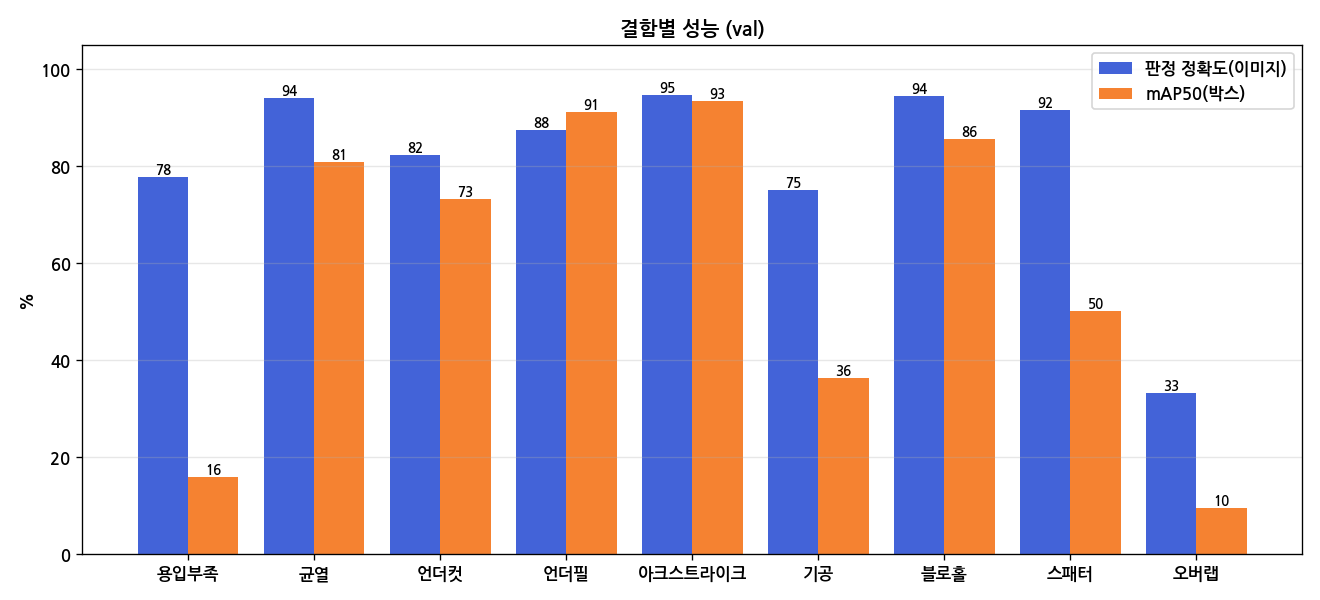

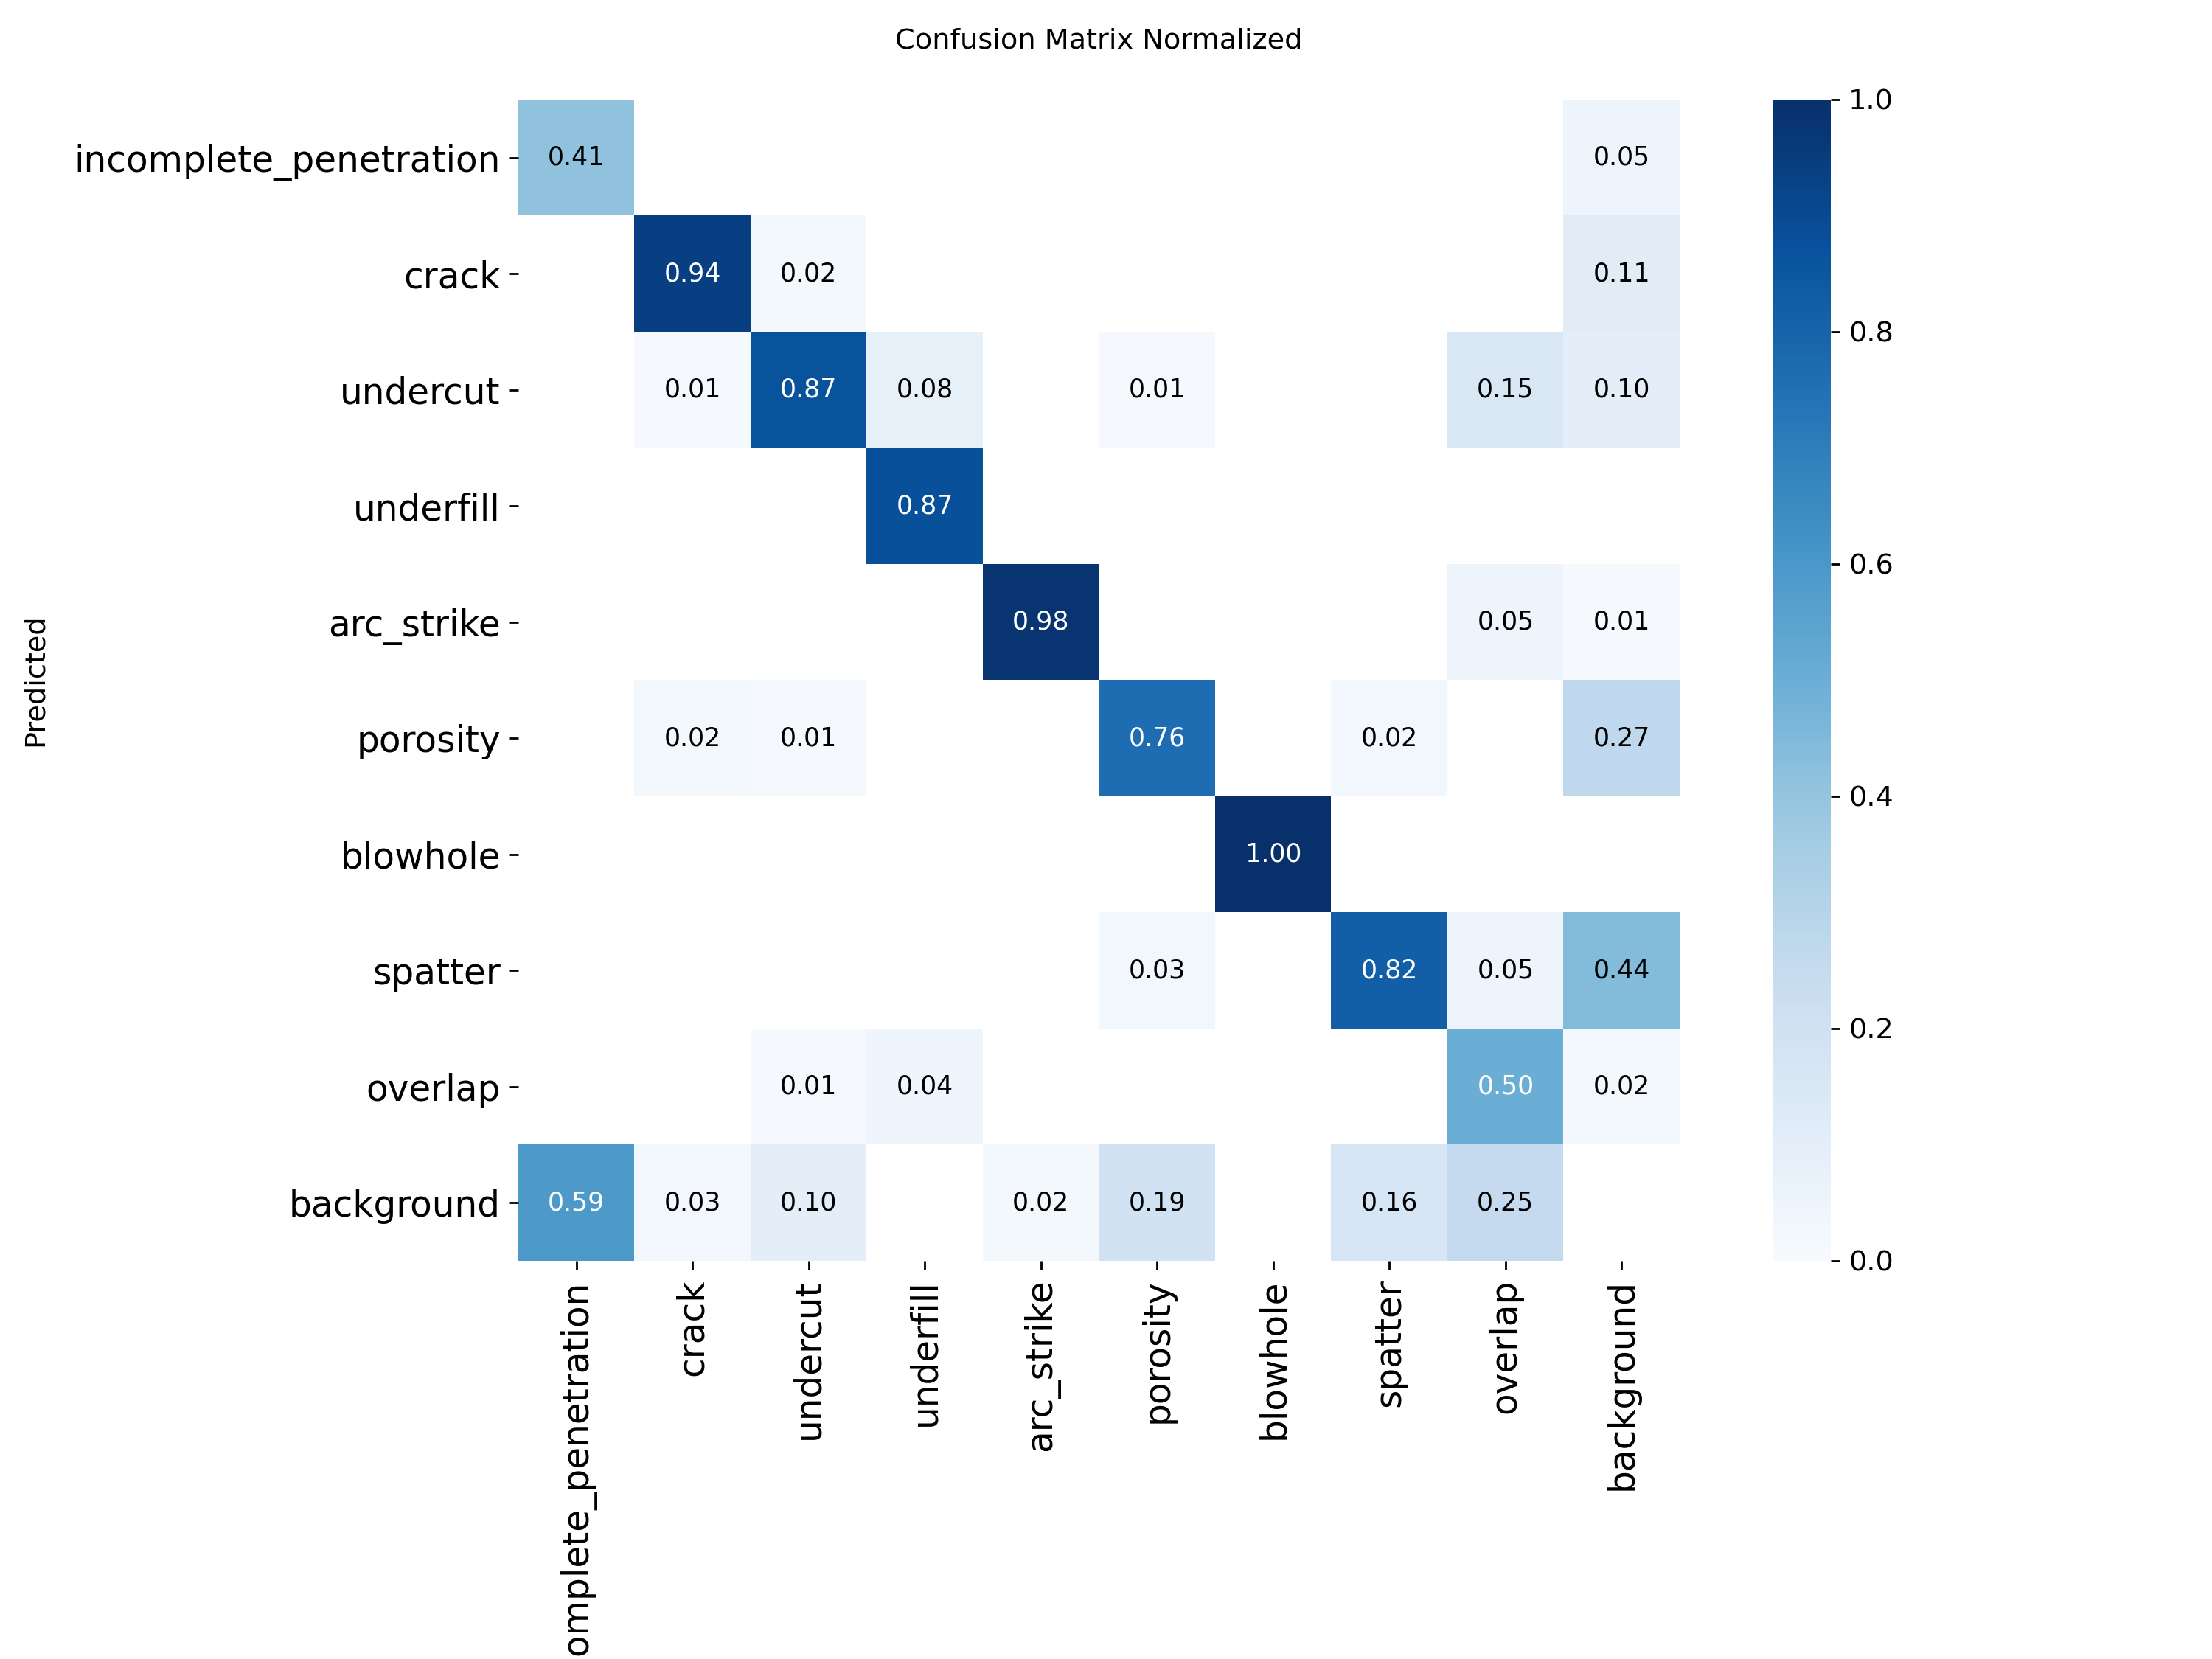

### test

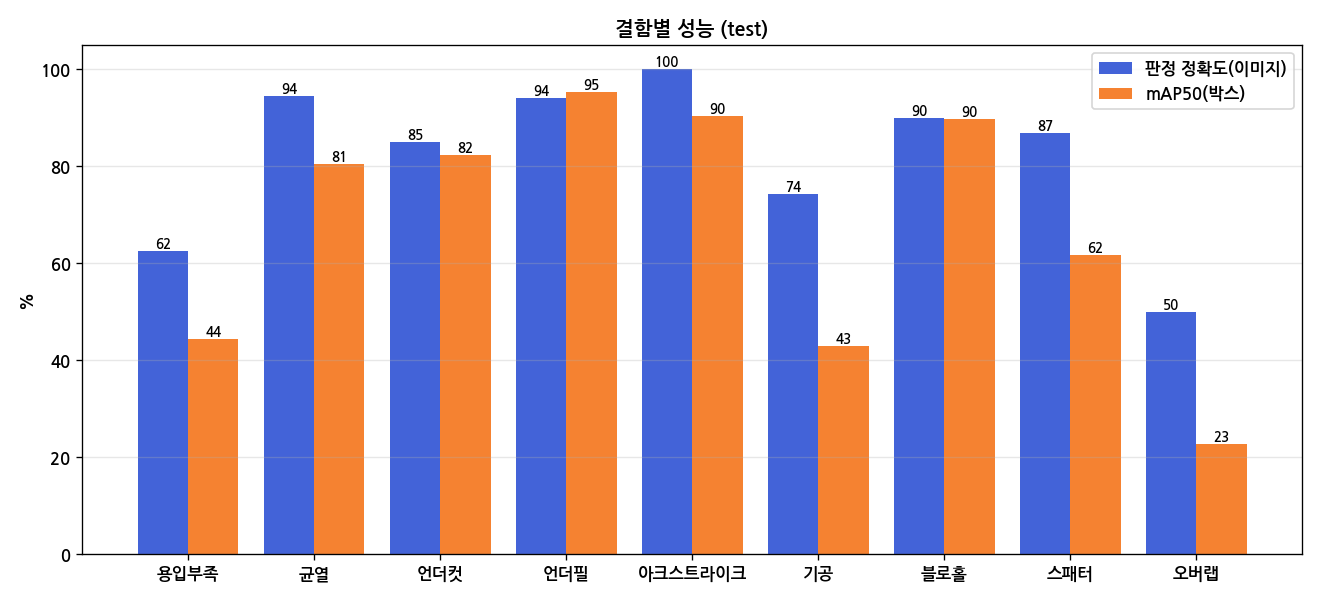

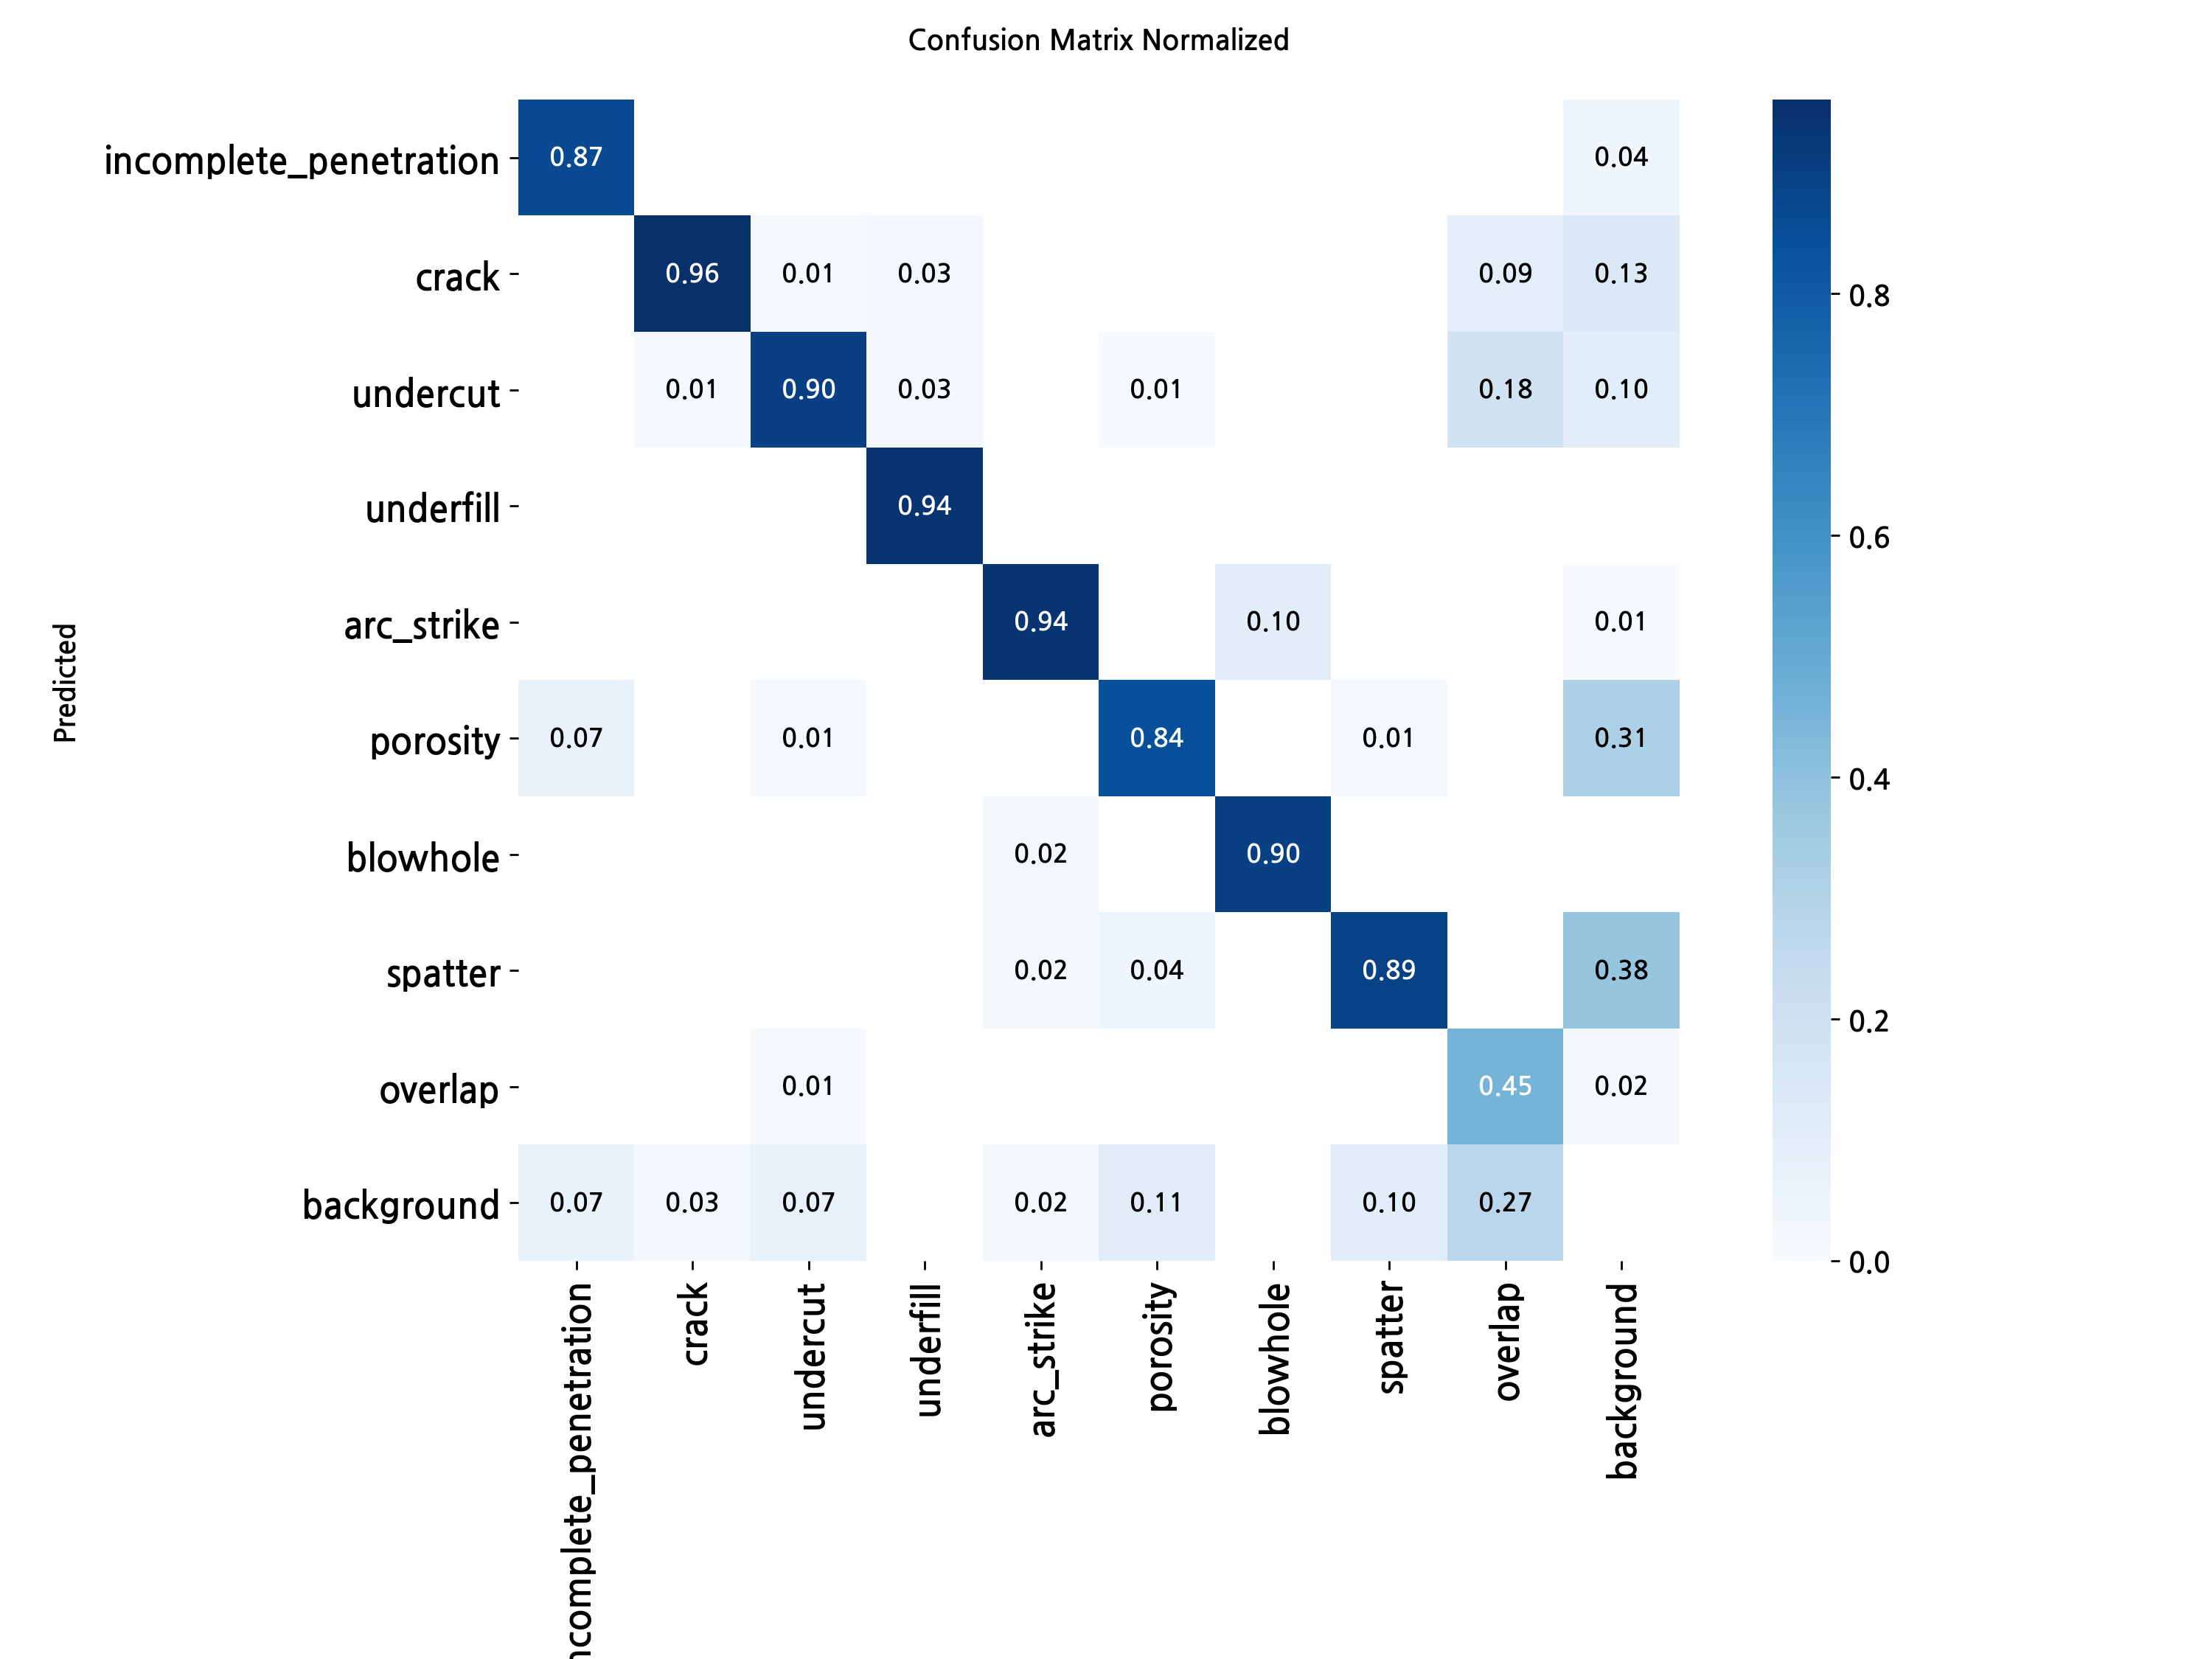

In [9]:
for split in ['val', 'test']:
    display(Markdown(f'### {split}'))
    display(Image(str(cfg.report_dir / f'{split}_per_class.png')))
    display(Image(str(cfg.report_dir / f'{split}_confusion_matrix.png'), width=700))

## 6. 결과 묶기 → Drive `BC_Project/results.zip`

In [10]:
import zipfile
run = cfg.runs_dir / cfg.run_name
out = DRIVE / 'results.zip'
with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(cfg.best_model, 'models/weld_best.pt')
    for f in cfg.report_dir.iterdir():
        z.write(f, f'reports/{f.name}')
    for f in run.glob('*.*'):        # results.csv, 학습 곡선 등
        if f.is_file():
            z.write(f, f'runs/{cfg.run_name}/{f.name}')
print(out, f'{out.stat().st_size / 1e6:.1f} MB')

/content/drive/MyDrive/BC_Project/results.zip 25.3 MB
